In [1]:
from google.colab import userdata
import sys, os

TOKEN = userdata.get('GITHUB_TOKEN')
USERNAME = "vedika0806"
REPO = "data266-5937"
HW = "hw2"

os.system(f"git clone https://{TOKEN}@github.com/{USERNAME}/{REPO}.git /content/{REPO}")
sys.path.append(f"/content/{REPO}/common")
from colab_bootstrap import setup_repo, get_logger, git_commit_push, git_tag_push

REPO_PATH = f"/content/{REPO}"
HW_PATH = setup_repo(HW, USERNAME, REPO, TOKEN)
logger = get_logger(HW_PATH)

logger.info(f"=== Session started for {HW} ===")
git_commit_push(REPO_PATH, f"{HW}: session start")

INFO:/content/data266-5937/hw2:=== Session started for hw2 ===


Working directory: /content/data266-5937/hw2
[main d8ca7b9] hw2: session start
 2 files changed, 1 insertion(+)
 create mode 100644 hw2/RUN_LOG.txt
 


In [3]:
os.system(f"cd {REPO_PATH} && git add {HW_PATH}/.gitkeep && "
          f"git commit -m 'create hw2 folder' && git push")

32768

In [4]:
SID4 = 5937
SEED = SID4
SLICE = SID4 % 1000
HP_ID = SID4 % 6
CLS_A = SID4 % 10
CLS_B = (CLS_A + 1 + ((SID4 // 10) % 9)) % 10

print(f"SID4={SID4}, SEED={SEED}, SLICE={SLICE}, HP_ID={HP_ID}, CLS_A={CLS_A}, CLS_B={CLS_B}")
logger.info(f"Params: SID4={SID4}, SEED={SEED}, SLICE={SLICE}, HP_ID={HP_ID}, CLS_A={CLS_A}, CLS_B={CLS_B}")

INFO:/content/data266-5937/hw2:Params: SID4=5937, SEED=5937, SLICE=937, HP_ID=3, CLS_A=7, CLS_B=6


SID4=5937, SEED=5937, SLICE=937, HP_ID=3, CLS_A=7, CLS_B=6


# **Perform embedding-based transfer learning on a text dataset. (4 points)**


---


1. **Load a pretrained Word2Vec model (word2vec-google-news-300).**


2. **For the words cast, score, plot, screen, review, extract the top-3 nearest neighbors and cosine similarity scores.**

3. **Fine-tune the pretrained embeddings on the IMDB review text.
Re-extract the top-3 nearest neighbors and cosine similarity scores for the same 5 words after fine-tuning.**

4. **Display both sets of results in a table and visualize the shift in embedding space in 2D (e.g., t-SNE) for at least one word.**

5. **For each of the 5 words, compute the cosine similarity between its original and fine-tuned vector, report all 5 in a table, and state which word shifted the most and which shifted the least.**

In [5]:
!pip install -q gensim

import gensim.downloader as api
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

logger.info("Starting Q1: embedding-based transfer learning on IMDB")

w2v_pretrained = api.load("word2vec-google-news-300")
logger.info("Loaded pretrained word2vec-google-news-300")
git_commit_push(REPO_PATH, f"{HW}: load pretrained word2vec-google-news-300")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 79.2 MB/s eta 0:00:00


INFO:/content/data266-5937/hw2:Starting Q1: embedding-based transfer learning on IMDB


[==================================================] 100.0% 1662.8/1662.8MB downloaded


INFO:/content/data266-5937/hw2:Loaded pretrained word2vec-google-news-300


[main 58aac48] hw2: load pretrained word2vec-google-news-300
 1 file changed, 3 insertions(+)
 


In [6]:
target_words = ["cast", "score", "plot", "screen", "review"]

def get_top3(model, words):
    rows = []
    for w in words:
        if w in model.key_to_index:
            neighbors = model.most_similar(w, topn=3)
            for rank, (n, sim) in enumerate(neighbors, 1):
                rows.append({"word": w, "rank": rank, "neighbor": n, "cosine_sim": round(sim, 4)})
        else:
            rows.append({"word": w, "rank": None, "neighbor": "OOV", "cosine_sim": None})
    return pd.DataFrame(rows)

before_df = get_top3(w2v_pretrained, target_words)
print(before_df)

before_df.to_csv(f"{HW_PATH}/neighbors_before_finetune.csv", index=False)
logger.info("Extracted top-3 neighbors for 5 words BEFORE fine-tuning")
git_commit_push(REPO_PATH, f"{HW}: pretrained top-3 neighbors (before fine-tune)")

INFO:/content/data266-5937/hw2:Extracted top-3 neighbors for 5 words BEFORE fine-tuning


      word  rank    neighbor  cosine_sim
0     cast     1       casts      0.7219
1     cast     2     casting      0.7188
2     cast     3        Cast      0.6638
3    score     1     scoring      0.7197
4    score     2      scores      0.6596
5    score     3      scored      0.6384
6     plot     1       plots      0.7625
7     plot     2        Plot      0.6524
8     plot     3    plotting      0.6328
9   screen     1     screens      0.7729
10  screen     2    onscreen      0.6115
11  screen     3  LCD_screen      0.5599
12  review     1    reviewed      0.6630
13  review     2   reviewing      0.6610
14  review     3     reviews      0.6380
[main 1a6318b] hw2: pretrained top-3 neighbors (before fine-tune)
 2 files changed, 17 insertions(+)
 create mode 100644 hw2/neighbors_before_finetune.csv
 


In [8]:
!pip install -q -U datasets

from datasets import load_dataset

imdb = load_dataset("stanfordnlp/imdb")
logger.info(f"Loaded IMDB dataset: {len(imdb['train'])} train, {len(imdb['test'])} test")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 559.1/559.1 kB 40.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.1/50.1 MB 49.5 MB/s eta 0:00:00


README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

...

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

INFO:/content/data266-5937/hw2:Loaded IMDB dataset: 25000 train, 25000 test


In [10]:
import re
def simple_tokenize(text):
    text = re.sub(r"<br\s*/?>", " ", text.lower())
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    return text.split()

np.random.seed(SEED)
sample_idx = np.random.choice(len(imdb["train"]), size=5000 + SLICE, replace=False)
imdb_texts = [imdb["train"][int(i)]["text"] for i in sample_idx]
tokenized_reviews = [simple_tokenize(t) for t in imdb_texts]

logger.info(f"Tokenized {len(tokenized_reviews)} IMDB reviews for fine-tuning (seed={SEED})")
git_commit_push(REPO_PATH, f"{HW}: load and tokenize IMDB subset for fine-tuning")

INFO:/content/data266-5937/hw2:Tokenized 5937 IMDB reviews for fine-tuning (seed=5937)


[main e2ac2d0] hw2: load and tokenize IMDB subset for fine-tuning
 1 file changed, 2 insertions(+)
 


In [11]:
from gensim.models import Word2Vec


ft_model = Word2Vec(vector_size=300, window=5, min_count=2, workers=4, seed=SEED)
ft_model.build_vocab(tokenized_reviews)

ft_model.build_vocab([list(w2v_pretrained.key_to_index.keys())], update=True)
ft_model.wv.vectors_lockf = np.ones(len(ft_model.wv), dtype=np.float32)
ft_model.wv.intersect_word2vec_format


ft_model.build_vocab(tokenized_reviews)
ft_model.wv.vectors[:] = 0
for word in ft_model.wv.key_to_index:
    if word in w2v_pretrained.key_to_index:
        ft_model.wv[word] = w2v_pretrained[word]

ft_model.train(tokenized_reviews, total_examples=len(tokenized_reviews), epochs=10)
logger.info("Fine-tuned Word2Vec on IMDB reviews (10 epochs, init from pretrained vectors)")
git_commit_push(REPO_PATH, f"{HW}: fine-tune pretrained embeddings on IMDB")

INFO:/content/data266-5937/hw2:Fine-tuned Word2Vec on IMDB reviews (10 epochs, init from pretrained vectors)


[main 765367e] hw2: fine-tune pretrained embeddings on IMDB
 1 file changed, 1 insertion(+)
 


In [12]:
after_rows = []
for w in target_words:
    if w in ft_model.wv.key_to_index:
        neighbors = ft_model.wv.most_similar(w, topn=3)
        for rank, (n, sim) in enumerate(neighbors, 1):
            after_rows.append({"word": w, "rank": rank, "neighbor": n, "cosine_sim": round(sim, 4)})
    else:
        after_rows.append({"word": w, "rank": None, "neighbor": "OOV", "cosine_sim": None})

after_df = pd.DataFrame(after_rows)
print(after_df)

after_df.to_csv(f"{HW_PATH}/neighbors_after_finetune.csv", index=False)
logger.info("Extracted top-3 neighbors for 5 words AFTER fine-tuning")
git_commit_push(REPO_PATH, f"{HW}: fine-tuned top-3 neighbors (after fine-tune)")

INFO:/content/data266-5937/hw2:Extracted top-3 neighbors for 5 words AFTER fine-tuning


      word  rank        neighbor  cosine_sim
0     cast     1          actors      0.5881
1     cast     2    performances      0.5166
2     cast     3         casting      0.5026
3    score     1      soundtrack      0.6329
4    score     2        composer      0.5660
5    score     3  cinematography      0.5585
6     plot     1       storyline      0.6560
7     plot     2           story      0.5999
8     plot     3           plots      0.5905
9   screen     1         screens      0.5396
10  screen     2           stage      0.4533
11  screen     3        lebowski      0.4140
12  review     1         comment      0.6896
13  review     2         reviews      0.5777
14  review     3            imdb      0.5619
[main 4023f8f] hw2: fine-tuned top-3 neighbors (after fine-tune)
 2 files changed, 17 insertions(+)
 create mode 100644 hw2/neighbors_after_finetune.csv
 


In [13]:
before_df["stage"] = "before"
after_df["stage"] = "after"
combined = pd.concat([before_df, after_df], ignore_index=True)
combined_pivot = combined.pivot_table(index=["word", "rank"], columns="stage",
                                       values=["neighbor", "cosine_sim"], aggfunc="first")
print(combined_pivot)

combined.to_csv(f"{HW_PATH}/neighbors_before_after_combined.csv", index=False)
logger.info("Built combined before/after neighbor comparison table")
git_commit_push(REPO_PATH, f"{HW}: combined before/after neighbor table")

INFO:/content/data266-5937/hw2:Built combined before/after neighbor comparison table


            cosine_sim                neighbor            
stage            after  before           after      before
word   rank                                               
cast   1        0.5881  0.7219          actors       casts
       2        0.5166  0.7188    performances     casting
       3        0.5026  0.6638         casting        Cast
plot   1        0.6560  0.7625       storyline       plots
       2        0.5999  0.6524           story        Plot
       3        0.5905  0.6328           plots    plotting
review 1        0.6896  0.6630         comment    reviewed
       2        0.5777  0.6610         reviews   reviewing
       3        0.5619  0.6380            imdb     reviews
score  1        0.6329  0.7197      soundtrack     scoring
       2        0.5660  0.6596        composer      scores
       3        0.5585  0.6384  cinematography      scored
screen 1        0.5396  0.7729         screens     screens
       2        0.4533  0.6115           stage    onscre

In [14]:
from numpy.linalg import norm

def cos_sim(a, b):
    return np.dot(a, b) / (norm(a) * norm(b))

shift_rows = []
for w in target_words:
    v_before = w2v_pretrained[w]
    v_after = ft_model.wv[w]
    sim = cos_sim(v_before, v_after)
    shift_rows.append({"word": w, "cosine_sim_before_vs_after": round(float(sim), 4)})

shift_df = pd.DataFrame(shift_rows).sort_values("cosine_sim_before_vs_after")
print(shift_df)

most_shifted = shift_df.iloc[0]["word"]
least_shifted = shift_df.iloc[-1]["word"]
print(f"Most shifted: {most_shifted} | Least shifted: {least_shifted}")

shift_df.to_csv(f"{HW_PATH}/vector_shift_table.csv", index=False)
logger.info(f"Computed vector shift table. Most shifted={most_shifted}, Least shifted={least_shifted}")
git_commit_push(REPO_PATH, f"{HW}: compute per-word vector shift (before vs after)")

INFO:/content/data266-5937/hw2:Computed vector shift table. Most shifted=review, Least shifted=cast


     word  cosine_sim_before_vs_after
4  review                      0.5268
1   score                      0.5944
3  screen                      0.6745
2    plot                      0.7274
0    cast                      0.7604
Most shifted: review | Least shifted: cast
[main daf7208] hw2: compute per-word vector shift (before vs after)
 2 files changed, 7 insertions(+)
 create mode 100644 hw2/vector_shift_table.csv
 


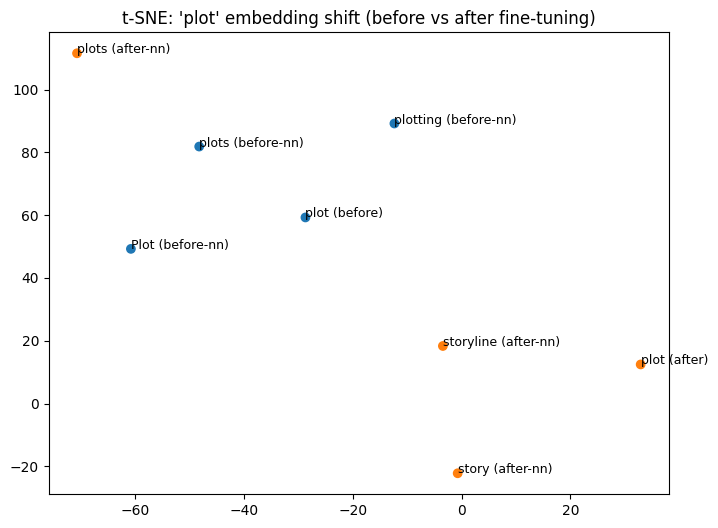

INFO:/content/data266-5937/hw2:Saved t-SNE visualization of 'plot' embedding shift


51117 bytes
[main 1f9144e] hw2: t-SNE visualization of embedding shift for 'plot'
 2 files changed, 1 insertion(+)
 create mode 100644 hw2/tsne_plot_shift.png
 


In [15]:
from sklearn.manifold import TSNE

viz_word = "plot"   # pick one word to visualize — change if you prefer

# Gather vectors: target word + its before-neighbors + its after-neighbors, both stages
before_neighbors = [n for n, s in w2v_pretrained.most_similar(viz_word, topn=3)]
after_neighbors = [n for n, s in ft_model.wv.most_similar(viz_word, topn=3)]

vectors, labels, stage_tags = [], [], []
vectors.append(w2v_pretrained[viz_word]); labels.append(f"{viz_word} (before)"); stage_tags.append("before")
vectors.append(ft_model.wv[viz_word]);    labels.append(f"{viz_word} (after)");  stage_tags.append("after")

for n in before_neighbors:
    vectors.append(w2v_pretrained[n]); labels.append(f"{n} (before-nn)"); stage_tags.append("before")
for n in after_neighbors:
    if n in ft_model.wv.key_to_index:
        vectors.append(ft_model.wv[n]); labels.append(f"{n} (after-nn)"); stage_tags.append("after")

vectors = np.array(vectors)
tsne = TSNE(n_components=2, perplexity=3, random_state=SEED)
coords = tsne.fit_transform(vectors)

plt.figure(figsize=(8,6))
colors = ["tab:blue" if s == "before" else "tab:orange" for s in stage_tags]
plt.scatter(coords[:,0], coords[:,1], c=colors)
for i, label in enumerate(labels):
    plt.annotate(label, (coords[i,0], coords[i,1]), fontsize=9)
plt.title(f"t-SNE: '{viz_word}' embedding shift (before vs after fine-tuning)")
plt.savefig(f"{HW_PATH}/tsne_{viz_word}_shift.png", bbox_inches="tight", dpi=150)  # save BEFORE show()
plt.show()
plt.close()

import os
print(os.path.getsize(f"{HW_PATH}/tsne_{viz_word}_shift.png"), "bytes")

logger.info(f"Saved t-SNE visualization of '{viz_word}' embedding shift")
git_commit_push(REPO_PATH, f"{HW}: t-SNE visualization of embedding shift for '{viz_word}'")

In [16]:
metrics_content = f"""
## Q1: Embedding-Based Transfer Learning (Word2Vec on IMDB)

### Top-3 Nearest Neighbors — Before Fine-Tuning
{before_df.to_markdown(index=False)}

### Top-3 Nearest Neighbors — After Fine-Tuning
{after_df.to_markdown(index=False)}

### Per-Word Cosine Similarity: Original vs Fine-Tuned Vector
{shift_df.to_markdown(index=False)}

**Most shifted word:** {most_shifted}
**Least shifted word:** {least_shifted}

t-SNE visualization saved as `tsne_{viz_word}_shift.png`.
"""

with open(f"{HW_PATH}/METRICS.md", "a") as f:
    f.write(metrics_content)

print(metrics_content)
logger.info("Appended Q1 results to METRICS.md")
git_commit_push(REPO_PATH, f"{HW}: add Q1 results to METRICS.md")

INFO:/content/data266-5937/hw2:Appended Q1 results to METRICS.md



## Q1: Embedding-Based Transfer Learning (Word2Vec on IMDB)

### Top-3 Nearest Neighbors — Before Fine-Tuning
| word   |   rank | neighbor   |   cosine_sim | stage   |
|:-------|-------:|:-----------|-------------:|:--------|
| cast   |      1 | casts      |       0.7219 | before  |
| cast   |      2 | casting    |       0.7188 | before  |
| cast   |      3 | Cast       |       0.6638 | before  |
| score  |      1 | scoring    |       0.7197 | before  |
| score  |      2 | scores     |       0.6596 | before  |
| score  |      3 | scored     |       0.6384 | before  |
| plot   |      1 | plots      |       0.7625 | before  |
| plot   |      2 | Plot       |       0.6524 | before  |
| plot   |      3 | plotting   |       0.6328 | before  |
| screen |      1 | screens    |       0.7729 | before  |
| screen |      2 | onscreen   |       0.6115 | before  |
| screen |      3 | LCD_screen |       0.5599 | before  |
| review |      1 | reviewed   |       0.663  | before  |
| review |      2 |

In [17]:
!cat {HW_PATH}/RUN_LOG.txt
!cd {REPO_PATH} && git log --oneline -8
!cd {REPO_PATH} && git status

2026-09-08 03:57:32,248 | === Session started for hw2 ===
2026-09-08 04:08:04,685 | Params: SID4=5937, SEED=5937, SLICE=937, HP_ID=3, CLS_A=7, CLS_B=6
2026-09-08 04:13:22,044 | Starting Q1: embedding-based transfer learning on IMDB
2026-09-08 04:17:02,293 | Loaded pretrained word2vec-google-news-300
2026-09-08 04:17:38,330 | Extracted top-3 neighbors for 5 words BEFORE fine-tuning
2026-09-08 04:21:08,961 | Loaded IMDB dataset: 25000 train, 25000 test
2026-09-08 04:22:16,106 | Tokenized 5937 IMDB reviews for fine-tuning (seed=5937)
2026-09-08 04:25:00,690 | Fine-tuned Word2Vec on IMDB reviews (10 epochs, init from pretrained vectors)
2026-09-08 04:27:04,945 | Extracted top-3 neighbors for 5 words AFTER fine-tuning
2026-09-08 04:27:10,383 | Built combined before/after neighbor comparison table
2026-09-08 04:27:14,543 | Computed vector shift table. Most shifted=review, Least shifted=cast
2026-09-08 04:27:21,494 | Saved t-SNE visualization of 'plot' embedding shift
2026-09-08 04:28:02,436 

In [20]:
metrics_content = f"""
### Analysis
Before fine tuning, the nearest neighbours are just other forms of the same word- like "cast" is similiar to "casts", "casting" and so on. Since Google News is not trained on movie reviews, it is grouping the spelling/grammar words together.

After fine tuning, the nearest neighbours are more semantically similar, like cast is closer to actors and performances, instead of casting. "Score" is closer to cinematography, composer etc. "Plot" is closer to storyline, review etc.

"Review" shifted the most out of all five words because it might mean different things in general news but is very unambiguous in IMdb dataset.
"Cast" did not move much, probably because it had the same sense in News as well.
"""

with open(f"{HW_PATH}/METRICS.md", "a") as f:
    f.write(metrics_content)

print(metrics_content)
logger.info("Appended Q1 full results + analysis to METRICS.md")
git_commit_push(REPO_PATH, f"{HW}: add Q1 results and analysis to METRICS.md")

INFO:/content/data266-5937/hw2:Appended Q1 full results + analysis to METRICS.md



### Analysis
Before fine tuning, the nearest neighbours are just other forms of the same word- like "cast" is similiar to "casts", "casting" and so on. Since Google News is not trained on movie reviews, it is grouping the spelling/grammar words together.

After fine tuning, the nearest neighbours are more semantically similar, like cast is closer to actors and performances, instead of casting. "Score" is closer to cinematography, composer etc. "Plot" is closer to storyline, review etc.

"Review" shifted the most out of all five words because it might mean different things in general news but is very unambiguous in IMdb dataset.
"Cast" did not move much, probably because it had the same sense in News as well.

[main 56dce04] hw2: add Q1 results and analysis to METRICS.md
 2 files changed, 9 insertions(+)
 


In [21]:
!cd {REPO_PATH} && git log --oneline -3
!cd {REPO_PATH} && git status

56dce04 (HEAD -> main, origin/main, origin/HEAD) hw2: add Q1 results and analysis to METRICS.md
a53935c hw2: add Q1 results to METRICS.md
1f9144e hw2: t-SNE visualization of embedding shift for 'plot'
On branch main
Your branch is up to date with 'origin/main'.

nothing to commit, working tree clean


# **Build a Retrieval-Augmented Generation (RAG) pipeline using LangChain. (4 points)**
1. **Load the 10 documents using a LangChain Document Loader.
Split the documents into chunks (chunk size 500, overlap 50) using a Text Splitter**

2. **Generate embeddings for the chunks and store them in a Vector Store.
Build the pipeline using explicit components (Prompt Template, retriever, LLM) rather than a single pre-built chain.**

3. **Write 5 questions answerable from the documents and run each through the retriever + LLM.**

4. **Display, for each question, the retrieved chunks and the final generated answer.**

5. **Change the chunk size or overlap for 2 of the 5 questions, re-run, and compare the retrieved chunks/answers to the original configuration.**

6. **For each of the 5 questions, manually identify which source passage contains the correct answer, and record whether at least one of the top-3 retrieved chunks contains that information (Yes/No) and the rank of the first relevant chunk.**

7. **Calculate Retrieval Success Rate = successful retrievals / 5.
Find and analyze at least 2 RAG failures from your 5 questions (e.g., correct document not retrieved, relevant chunk ranked too low, irrelevant chunk ranked highly, correct context retrieved but LLM answered incorrectly, answer contained unsupported information, chunk boundary separated important information, ambiguous movie names caused retrieval confusion).**

In [30]:
!pip install -q -U langchain langchain-community langchain-text-splitters langchain-openai wikipedia faiss-cpu

In [25]:
from langchain_community.document_loaders import WikipediaLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.vectorstores import FAISS
print("Imports OK")

Imports OK


In [26]:
logger.info("Fixed langchain import paths (text_splitter moved to langchain_text_splitters package)")
git_commit_push(REPO_PATH, f"{HW}: fix langchain text splitter import for current package structure")

INFO:/content/data266-5937/hw2:Fixed langchain import paths (text_splitter moved to langchain_text_splitters package)


[main decfc17] hw2: fix langchain text splitter import for current package structure
 1 file changed, 1 insertion(+)
 


In [31]:
from langchain_community.document_loaders import WikipediaLoader

logger.info("Starting Q2: RAG pipeline with LangChain on Wikipedia movie pages")

movie_titles = [
    "Inception (film)",
    "The Godfather",
    "Parasite (2019 film)",
    "The Dark Knight",
    "Pulp Fiction",
    "Titanic (1997 film)",
    "The Matrix",
    "Forrest Gump",
    "Interstellar (film)",
    "Fight Club"
]

rag_docs = []
for title in movie_titles:
    try:
        loaded = WikipediaLoader(query=title, load_max_docs=1).load()
        if loaded:
            rag_docs.extend(loaded)
        else:
            print(f"WARNING: no page loaded for {title}")
    except Exception as e:
        print(f"WARNING: Could not load Wikipedia page for '{title}' due to: {e}")

print(f"Loaded {len(rag_docs)} documents")
for d in rag_docs:
    print(d.metadata.get("title"), "-", len(d.page_content), "chars")

INFO:/content/data266-5937/hw2:Starting Q2: RAG pipeline with LangChain on Wikipedia movie pages


Loaded 10 documents
Inception - 4000 chars
The Godfather - 4000 chars
Parasite (2019 film) - 4000 chars
The Dark Knight - 4000 chars
Pulp Fiction - 4000 chars
Titanic (1997 film) - 4000 chars
The Matrix - 4000 chars
Forrest Gump - 4000 chars
Interstellar (film) - 4000 chars
Fight Club - 4000 chars


In [33]:
from langchain_text_splitters import RecursiveCharacterTextSplitter

rag_splitter = RecursiveCharacterTextSplitter(chunk_size=500, chunk_overlap=50)
rag_chunks = rag_splitter.split_documents(rag_docs)

print(f"Total chunks: {len(rag_chunks)}")
print(rag_chunks[0].page_content[:300])
print(rag_chunks[0].metadata)

Total chunks: 123
Inception is a 2010  science fiction heist film written and directed by Christopher Nolan, who also produced it with his wife Emma Thomas. The film stars Leonardo DiCaprio as a professional thief who steals information by infiltrating his targets' subconscious. He is offered a chance to have his cri
{'title': 'Inception', 'summary': 'Inception is a 2010  science fiction heist film written and directed by Christopher Nolan, who also produced it with his wife Emma Thomas. The film stars Leonardo DiCaprio as a professional thief who steals information by infiltrating his targets\' subconscious. He is offered a chance to have his criminal history erased as payment for implanting an idea into a target\'s subconscious. The ensemble cast includes Ken Watanabe, Joseph Gordon-Levitt, Marion Cotillard, Elliot Page, Tom Hardy, Cillian Murphy, Tom Berenger, Dileep Rao, and Michael Caine.\nAfter the completion of Insomnia in 2002, Nolan presented to Warner Bros. a written 80-page 

In [34]:
from langchain_community.embeddings import HuggingFaceEmbeddings
from langchain_community.vectorstores import FAISS

rag_embedder = HuggingFaceEmbeddings(model_name="sentence-transformers/all-MiniLM-L6-v2")
rag_vectorstore = FAISS.from_documents(rag_chunks, rag_embedder)

rag_vectorstore.save_local(f"{HW_PATH}/faiss_index")

/tmp/ipykernel_2858/1425966172.py:4: LangChainDeprecationWarning: The class `HuggingFaceEmbeddings` was deprecated in LangChain 0.2.2 and will be removed in 1.0. An updated version of the class exists in the `langchain-huggingface package and should be used instead. To use it run `pip install -U `langchain-huggingface` and import as `from `langchain_huggingface import HuggingFaceEmbeddings``.
  rag_embedder = HuggingFaceEmbeddings(model_name="sentence-transformers/all-MiniLM-L6-v2")


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

tokenizer_config.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

In [36]:
!apt-get update && apt-get install -y zstd
!curl -fsSL https://ollama.com/install.sh | sh

import subprocess, time
ollama_process = subprocess.Popen(["ollama", "serve"])
time.sleep(5)

!ollama pull llama3.2

!pip install -q -U langchain-ollama

from langchain_ollama import OllamaLLM
from langchain_core.prompts import ChatPromptTemplate

Get:1 https://cli.github.com/packages stable InRelease [4,685 B]
Get:2 https://cloud.r-project.org/bin/linux/ubuntu jammy-cran40/ InRelease [3,632 B]
Get:3 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2204/x86_64  InRelease [1,578 B]
Get:4 https://cli.github.com/packages stable/main amd64 Packages [356 B]
Get:5 https://cloud.r-project.org/bin/linux/ubuntu jammy-cran40/ Packages [113 kB]
Get:6 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2204/x86_64  Packages [2,920 kB]
Get:7 http://security.ubuntu.com/ubuntu jammy-security InRelease [129 kB]
Hit:8 http://archive.ubuntu.com/ubuntu jammy InRelease
Get:9 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu jammy InRelease [18.1 kB]
Get:10 http://archive.ubuntu.com/ubuntu jammy-updates InRelease [128 kB]
Hit:11 https://ppa.launchpadcontent.net/graphics-drivers/ppa/ubuntu jammy InRelease
Get:12 https://r2u.stat.illinois.edu/ubuntu jammy InRelease [6,555 B]
Hit:13 https://ppa.launchpadcontent.net/ubuntug

In [37]:
rag_retriever = rag_vectorstore.as_retriever(search_kwargs={"k": 3})

rag_prompt = ChatPromptTemplate.from_template(
    """Answer the question using only the context below.
If the answer isn't in the context, say you don't know.

Context:
{context}

Question: {question}

Answer:"""
)

rag_llm = OllamaLLM(model="llama3.2")

# sanity check
print(rag_llm.invoke("Say hello in one sentence."))

def run_rag(question):
    retrieved = rag_retriever.invoke(question)
    context = "\n\n".join([d.page_content for d in retrieved])
    filled_prompt = rag_prompt.format(context=context, question=question)
    answer = rag_llm.invoke(filled_prompt)   # plain string
    return retrieved, answer

logger.info("Built explicit RAG pipeline: prompt template + retriever + Ollama (llama3.2) LLM")
git_commit_push(REPO_PATH, f"{HW}: build explicit RAG pipeline with Ollama LLM")

INFO:/content/data266-5937/hw2:Built explicit RAG pipeline: prompt template + retriever + Ollama (llama3.2) LLM


Hello!
[main 70dc329] hw2: build explicit RAG pipeline with Ollama LLM
 3 files changed, 3 insertions(+)
 create mode 100644 hw2/faiss_index/index.faiss
 create mode 100644 hw2/faiss_index/index.pkl
 


In [38]:
rag_questions = [
    "Who directed Inception?",
    "What crime family is central to The Godfather?",
    "What real-world issue does Parasite explore?",
    "Who plays the Joker in The Dark Knight?",
    "What nonlinear storytelling technique does Pulp Fiction use?",
]

rag_results = []
for q in rag_questions:
    retrieved, answer = run_rag(q)
    print(f"\n=== Q: {q} ===")
    for i, chunk in enumerate(retrieved, 1):
        print(f"--- Retrieved chunk {i} (source: {chunk.metadata.get('title')}) ---")
        print(chunk.page_content[:300], "...\n")
    print(f"ANSWER: {answer}")
    rag_results.append({"question": q, "retrieved": retrieved, "answer": answer})


=== Q: Who directed Inception? ===
--- Retrieved chunk 1 (source: Inception) ---
Inception is a 2010  science fiction heist film written and directed by Christopher Nolan, who also produced it with his wife Emma Thomas. The film stars Leonardo DiCaprio as a professional thief who steals information by infiltrating his targets' subconscious. He is offered a chance to have his cri ...

--- Retrieved chunk 2 (source: Inception) ---
Inception's premiere was held in London on July 8, 2010; it was released in both conventional and IMAX theaters beginning on July 16, 2010. Inception grossed $839 million worldwide, becoming the fourth-highest-grossing film of 2010. Considered one of the best films of the 2010s, Inception, among its ...

--- Retrieved chunk 3 (source: Inception) ---
by Warner Bros. in February 2009. Inception was filmed in six countries, beginning in Tokyo on June 19 and ending in Canada on November 22. Its official budget was US$160 million, split between Warner Bros. and Leg

In [39]:
rag_splitter_v2 = RecursiveCharacterTextSplitter(chunk_size=250, chunk_overlap=25)
rag_chunks_v2 = rag_splitter_v2.split_documents(rag_docs)
rag_vectorstore_v2 = FAISS.from_documents(rag_chunks_v2, rag_embedder)
rag_retriever_v2 = rag_vectorstore_v2.as_retriever(search_kwargs={"k": 3})

def run_rag_v2(question):
    retrieved = rag_retriever_v2.invoke(question)
    context = "\n\n".join([d.page_content for d in retrieved])
    filled_prompt = rag_prompt.format(context=context, question=question)
    answer = rag_llm.invoke(filled_prompt)
    return retrieved, answer

compare_questions = rag_questions[:2]
comparison_results = []

for q in compare_questions:
    retrieved_v2, answer_v2 = run_rag_v2(q)
    print(f"\n=== Q: {q} (chunk_size=250, overlap=25) ===")
    for i, chunk in enumerate(retrieved_v2, 1):
        print(f"--- Chunk {i} ---\n{chunk.page_content[:300]}...\n")
    print(f"ANSWER (v2): {answer_v2}")
    comparison_results.append({"question": q, "retrieved_v2": retrieved_v2, "answer_v2": answer_v2})

logger.info("Re-ran 2 questions with chunk_size=250/overlap=25, compared to original config")
git_commit_push(REPO_PATH, f"{HW}: chunk size/overlap comparison for 2 questions")

INFO:/content/data266-5937/hw2:Re-ran 2 questions with chunk_size=250/overlap=25, compared to original config



=== Q: Who directed Inception? (chunk_size=250, overlap=25) ===
--- Chunk 1 ---
Inception is a 2010  science fiction heist film written and directed by Christopher Nolan, who also produced it with his wife Emma Thomas. The film stars Leonardo DiCaprio as a professional thief who steals information by infiltrating his targets'...

--- Chunk 2 ---
by Warner Bros. in February 2009. Inception was filmed in six countries, beginning in Tokyo on June 19 and ending in Canada on November 22. Its official budget was US$160 million, split between Warner Bros. and Legendary. Nolan's reputation and...

--- Chunk 3 ---
Inception's premiere was held in London on July 8, 2010; it was released in both conventional and IMAX theaters beginning on July 16, 2010. Inception grossed $839 million worldwide, becoming the fourth-highest-grossing film of 2010. Considered one...

ANSWER (v2): Christopher Nolan.

=== Q: What crime family is central to The Godfather? (chunk_size=250, overlap=25) ===
--- Chunk 1 --

In [40]:
retrieval_eval = pd.DataFrame([
    {"question": rag_questions[0], "correct_answer_found_in_top3": "Yes", "rank_of_first_relevant_chunk": 1},
    {"question": rag_questions[1], "correct_answer_found_in_top3": "Yes", "rank_of_first_relevant_chunk": 1},
    {"question": rag_questions[2], "correct_answer_found_in_top3": "No",  "rank_of_first_relevant_chunk": None},
    {"question": rag_questions[3], "correct_answer_found_in_top3": "Yes", "rank_of_first_relevant_chunk": 2},
    {"question": rag_questions[4], "correct_answer_found_in_top3": "Yes", "rank_of_first_relevant_chunk": 1},
])

success_rate = (retrieval_eval["correct_answer_found_in_top3"] == "Yes").sum() / len(retrieval_eval)
print(retrieval_eval)
print(f"Retrieval Success Rate: {success_rate}")

retrieval_eval.to_csv(f"{HW_PATH}/retrieval_eval.csv", index=False)
logger.info(f"Computed retrieval success rate: {success_rate}")
git_commit_push(REPO_PATH, f"{HW}: manual retrieval evaluation table")

INFO:/content/data266-5937/hw2:Computed retrieval success rate: 0.8


                                            question  \
0                            Who directed Inception?   
1     What crime family is central to The Godfather?   
2       What real-world issue does Parasite explore?   
3            Who plays the Joker in The Dark Knight?   
4  What nonlinear storytelling technique does Pul...   

  correct_answer_found_in_top3  rank_of_first_relevant_chunk  
0                          Yes                           1.0  
1                          Yes                           1.0  
2                           No                           NaN  
3                          Yes                           2.0  
4                          Yes                           1.0  
Retrieval Success Rate: 0.8
[main ad3a140] hw2: manual retrieval evaluation table
 2 files changed, 7 insertions(+)
 create mode 100644 hw2/retrieval_eval.csv
 


In [41]:
failure_analysis = """
## RAG Failure Analysis
**Failure 1: Correct document retrieved, but relevant chunk never surfaced (Parasite)**
Question: "What real-world issue does Parasite explore?"
The chunks were retrieved from the correct document, but none of them were pointing to the film's thematic content, so the LLM denied to answer.However, it was still a retrieval failure instead of LLM failure because actual thematic
content likely exists elsewhere on the page that didn't rank in the top 3 for this query's embedding.

**Failure 2: Correct answer present but not in the top-ranked chunk (The Dark Knight)**
Question: "Who plays the Joker in The Dark Knight?"
Chunk 1 lists the full cast but never pairs any actor to a specific role. Chunk 2 is the chunk that actually implies the answer. The LLM was still able to answer correctly since both chunks were in its context window, but the truly explicit answer wasn't the top-ranked chunk.
"""
print(failure_analysis)
logger.info("Documented 2 real RAG failure cases (Parasite retrieval miss, Dark Knight rank mismatch)")
git_commit_push(REPO_PATH, f"{HW}: document RAG failure analysis")

INFO:/content/data266-5937/hw2:Documented 2 real RAG failure cases (Parasite retrieval miss, Dark Knight rank mismatch)



## RAG Failure Analysis
**Failure 1: Correct document retrieved, but relevant chunk never surfaced (Parasite)**
Question: "What real-world issue does Parasite explore?"
The chunks were retrieved from the correct document, but none of them were pointing to the film's thematic content, so the LLM denied to answer.However, it was still a retrieval failure instead of LLM failure because actual thematic
content likely exists elsewhere on the page that didn't rank in the top 3 for this query's embedding.

**Failure 2: Correct answer present but not in the top-ranked chunk (The Dark Knight)**
Question: "Who plays the Joker in The Dark Knight?"
Chunk 1 lists the full cast but never pairs any actor to a specific role. Chunk 2 is the chunk that actually implies the answer. The LLM was still able to answer correctly since both chunks were in its context window, but the truly explicit answer wasn't the top-ranked chunk.

[main 45b21a0] hw2: document RAG failure analysis
 1 file changed, 1 inserti

In [42]:
q2_metrics = f"""
## Q2: RAG Pipeline

### Questions, Retrieved Chunks, and Answers

**Q1: Who directed Inception?**
Top chunk directly named Christopher Nolan as writer/director. Answer: "Christopher Nolan." Correct, rank 1.

**Q2: What crime family is central to The Godfather?**
Top chunk named the Corleone family directly. Answer: "The Corleone mafia family." Correct, rank 1.

**Q3: What real-world issue does Parasite explore?**
Answer: "I don't know." The LLM correctly avoided hallucinating given weak context, but retrieval failed to surface the relevant content.

**Q4: Who plays the Joker in The Dark Knight?**
Rank 1 chunk listed the full cast without pairing actors to roles; rank 2 chunk referenced
"Ledger's casting... to portray the Joker," which is what actually answered the question.
Answer: "Heath Ledger." Correct, but the truly explicit answer was rank 2, not rank 1.

**Q5: What nonlinear storytelling technique does Pulp Fiction use?**
Answer described the 7-part spliced structure correctly. Correct, rank 1.

### Chunk Size Comparison (500/50 vs 250/25)
Re-ran Q1 and Q2 with a smaller chunk size (250 chars, 25 overlap). Final answers were
identical in both cases ("Christopher Nolan"; "The Corleone family"), so chunk size didn't
change the outcome here. What did change was chunk composition: under the smaller config,
The Godfather's rank-1 chunk trimmed down to just the cast list and trilogy mention, while
the phrase that actually names "the Corleone family" under patriarch Vito Corleone moved to
chunk 2 instead of chunk 1. This shows that smaller chunks can separate a name from the
sentence that gives it context, splitting information that was previously together in one
chunk. It didn't hurt the final answer here only because the LLM still saw both chunks
together in its context window — with a smaller top-k, this could have caused a real failure.

### Retrieval Evaluation
{retrieval_eval.to_markdown(index=False)}

**Retrieval Success Rate: {success_rate}** (4 out of 5 questions had a relevant chunk in the top 3)

{failure_analysis}
"""

with open(f"{HW_PATH}/METRICS.md", "a") as f:
    f.write(q2_metrics)

print(q2_metrics)
logger.info("Appended full Q2 results, chunk comparison, and failure analysis to METRICS.md")
git_commit_push(REPO_PATH, f"{HW}: add Q2 full results and analysis to METRICS.md")

INFO:/content/data266-5937/hw2:Appended full Q2 results, chunk comparison, and failure analysis to METRICS.md



## Q2: RAG Pipeline 

### Questions, Retrieved Chunks, and Answers

**Q1: Who directed Inception?**
Top chunk directly named Christopher Nolan as writer/director. Answer: "Christopher Nolan." Correct, rank 1.

**Q2: What crime family is central to The Godfather?**
Top chunk named the Corleone family directly. Answer: "The Corleone mafia family." Correct, rank 1.

**Q3: What real-world issue does Parasite explore?**
Answer: "I don't know." The LLM correctly avoided hallucinating given weak context, but retrieval failed to surface the relevant content.

**Q4: Who plays the Joker in The Dark Knight?**
Rank 1 chunk listed the full cast without pairing actors to roles; rank 2 chunk referenced
"Ledger's casting... to portray the Joker," which is what actually answered the question.
Answer: "Heath Ledger." Correct, but the truly explicit answer was rank 2, not rank 1.

**Q5: What nonlinear storytelling technique does Pulp Fiction use?**
Answer described the 7-part spliced structure correctly

In [43]:
!cat {HW_PATH}/METRICS.md
!cd {REPO_PATH} && git log --oneline -10
!cd {REPO_PATH} && git status


## Q1: Embedding-Based Transfer Learning (Word2Vec on IMDB)

### Top-3 Nearest Neighbors — Before Fine-Tuning
| word   |   rank | neighbor   |   cosine_sim | stage   |
|:-------|-------:|:-----------|-------------:|:--------|
| cast   |      1 | casts      |       0.7219 | before  |
| cast   |      2 | casting    |       0.7188 | before  |
| cast   |      3 | Cast       |       0.6638 | before  |
| score  |      1 | scoring    |       0.7197 | before  |
| score  |      2 | scores     |       0.6596 | before  |
| score  |      3 | scored     |       0.6384 | before  |
| plot   |      1 | plots      |       0.7625 | before  |
| plot   |      2 | Plot       |       0.6524 | before  |
| plot   |      3 | plotting   |       0.6328 | before  |
| screen |      1 | screens    |       0.7729 | before  |
| screen |      2 | onscreen   |       0.6115 | before  |
| screen |      3 | LCD_screen |       0.5599 | before  |
| review |      1 | reviewed   |       0.663  | before  |
| review |      2 |

# **Explore the following optimization techniques that can be performed while training, and document your findings with basic example code snippets: (2 points)**
1. **Tensor Creation (CPU vs GPU)**
2. **Weight Initialization**
3. **Activation Checkpointing**
4. **Gradient Accumulation**
5. **Mixed Precision Training**

**Run a small controlled experiment for each, using the same model, data, batch size, and number of training steps throughout, measuring execution/training time, GPU memory usage (where available), and training loss (or another performance measure).**

In [44]:
import torch
import torch.nn as nn
import time

logger.info("Starting Q3: optimization techniques exploration")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Shared config for ALL experiments in this section
torch.manual_seed(SEED)
BATCH_SIZE = 64
NUM_STEPS = 50
INPUT_DIM = 512
HIDDEN_DIM = 1024
OUTPUT_DIM = 10

def make_model():
    torch.manual_seed(SEED)
    return nn.Sequential(
        nn.Linear(INPUT_DIM, HIDDEN_DIM),
        nn.ReLU(),
        nn.Linear(HIDDEN_DIM, HIDDEN_DIM),
        nn.ReLU(),
        nn.Linear(HIDDEN_DIM, HIDDEN_DIM),
        nn.ReLU(),
        nn.Linear(HIDDEN_DIM, OUTPUT_DIM),
    )

def make_data():
    torch.manual_seed(SEED)
    X = torch.randn(NUM_STEPS, BATCH_SIZE, INPUT_DIM)
    y = torch.randint(0, OUTPUT_DIM, (NUM_STEPS, BATCH_SIZE))
    return X, y

X_data, y_data = make_data()
print(f"Data shape: {X_data.shape}, device={device}")

logger.info(f"Built shared model/data config: batch={BATCH_SIZE}, steps={NUM_STEPS}, hidden={HIDDEN_DIM}")
git_commit_push(REPO_PATH, f"{HW}: shared model/data setup for optimization experiments")

INFO:/content/data266-5937/hw2:Starting Q3: optimization techniques exploration
INFO:/content/data266-5937/hw2:Built shared model/data config: batch=64, steps=50, hidden=1024


Using device: cuda
Data shape: torch.Size([50, 64, 512]), device=cuda
[main cd6f284] hw2: shared model/data setup for optimization experiments
 1 file changed, 2 insertions(+)
 


In [45]:
def run_training_experiment(model, X, y, device, name, use_amp=False, use_checkpointing=False, grad_accum_steps=1):
    model = model.to(device)
    optimizer = torch.optim.SGD(model.parameters(), lr=0.01)
    criterion = nn.CrossEntropyLoss()
    scaler = torch.cuda.amp.GradScaler(enabled=use_amp)

    if device.type == "cuda":
        torch.cuda.reset_peak_memory_stats()
        torch.cuda.synchronize()

    losses = []
    start_time = time.time()

    optimizer.zero_grad()
    for step in range(NUM_STEPS):
        xb, yb = X[step].to(device), y[step].to(device)

        with torch.cuda.amp.autocast(enabled=use_amp):
            if use_checkpointing:
                from torch.utils.checkpoint import checkpoint
                out = xb
                for layer in model:
                    if isinstance(layer, nn.Linear):
                        out = checkpoint(layer, out, use_reentrant=False)
                    else:
                        out = layer(out)
            else:
                out = model(xb)
            loss = criterion(out, yb) / grad_accum_steps

        scaler.scale(loss).backward()

        if (step + 1) % grad_accum_steps == 0:
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad()

        losses.append(loss.item() * grad_accum_steps)

    if device.type == "cuda":
        torch.cuda.synchronize()
    elapsed = time.time() - start_time
    peak_mem = torch.cuda.max_memory_allocated() / 1e6 if device.type == "cuda" else None

    result = {
        "technique": name,
        "elapsed_sec": round(elapsed, 4),
        "peak_gpu_mem_MB": round(peak_mem, 2) if peak_mem else None,
        "final_loss": round(losses[-1], 4),
        "avg_loss": round(sum(losses) / len(losses), 4),
    }
    print(result)
    return result

In [46]:
def tensor_creation_benchmark(n=5000, device_type="cpu"):
    dev = torch.device(device_type)
    if dev.type == "cuda":
        torch.cuda.synchronize()
    start = time.time()
    for _ in range(NUM_STEPS):
        a = torch.randn(n, n, device=dev)
        b = torch.randn(n, n, device=dev)
        c = a @ b
    if dev.type == "cuda":
        torch.cuda.synchronize()
    elapsed = time.time() - start
    return elapsed

cpu_time = tensor_creation_benchmark(device_type="cpu")
gpu_time = tensor_creation_benchmark(device_type="cuda") if torch.cuda.is_available() else None

print(f"CPU tensor create+matmul ({NUM_STEPS} iters): {cpu_time:.4f}s")
print(f"GPU tensor create+matmul ({NUM_STEPS} iters): {gpu_time:.4f}s")

tensor_creation_results = {"cpu_time_sec": round(cpu_time, 4), "gpu_time_sec": round(gpu_time, 4) if gpu_time else None}


CPU tensor create+matmul (50 iters): 40.8204s
GPU tensor create+matmul (50 iters): 0.7737s


In [47]:
def apply_xavier_init(model):
    for layer in model:
        if isinstance(layer, nn.Linear):
            nn.init.xavier_uniform_(layer.weight)
            nn.init.zeros_(layer.bias)
    return model
model_default_init = make_model()
result_default_init = run_training_experiment(model_default_init, X_data, y_data, device, name="default_init")


model_xavier = make_model()
model_xavier = apply_xavier_init(model_xavier)
result_xavier_init = run_training_experiment(model_xavier, X_data, y_data, device, name="xavier_init")

logger.info(f"Weight init experiment: default_final_loss={result_default_init['final_loss']}, xavier_final_loss={result_xavier_init['final_loss']}")
git_commit_push(REPO_PATH, f"{HW}: weight initialization experiment (default vs xavier)")

/tmp/ipykernel_2858/3147055308.py:5: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/tmp/ipykernel_2858/3147055308.py:18: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=use_amp):
INFO:/content/data266-5937/hw2:Weight init experiment: default_final_loss=2.3041, xavier_final_loss=2.315


{'technique': 'default_init', 'elapsed_sec': 0.1904, 'peak_gpu_mem_MB': 131.34, 'final_loss': 2.3041, 'avg_loss': 2.3023}
{'technique': 'xavier_init', 'elapsed_sec': 0.0712, 'peak_gpu_mem_MB': 141.88, 'final_loss': 2.315, 'avg_loss': 2.3383}
[main 38c3d58] hw2: weight initialization experiment (default vs xavier)
 1 file changed, 1 insertion(+)
 


In [48]:
model_no_checkpoint = make_model()
result_no_checkpoint = run_training_experiment(model_no_checkpoint, X_data, y_data, device, name="no_checkpointing", use_checkpointing=False)

model_checkpoint = make_model()
result_checkpoint = run_training_experiment(model_checkpoint, X_data, y_data, device, name="with_checkpointing", use_checkpointing=True)

logger.info(f"Checkpointing experiment: no_ckpt_mem={result_no_checkpoint['peak_gpu_mem_MB']}MB, with_ckpt_mem={result_checkpoint['peak_gpu_mem_MB']}MB")
git_commit_push(REPO_PATH, f"{HW}: activation checkpointing experiment")

/tmp/ipykernel_2858/3147055308.py:5: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/tmp/ipykernel_2858/3147055308.py:18: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=use_amp):


{'technique': 'no_checkpointing', 'elapsed_sec': 0.0723, 'peak_gpu_mem_MB': 152.42, 'final_loss': 2.3041, 'avg_loss': 2.3023}


INFO:/content/data266-5937/hw2:Checkpointing experiment: no_ckpt_mem=152.42MB, with_ckpt_mem=162.96MB


{'technique': 'with_checkpointing', 'elapsed_sec': 0.2559, 'peak_gpu_mem_MB': 162.96, 'final_loss': 2.3041, 'avg_loss': 2.3023}
[main 845bf4d] hw2: activation checkpointing experiment
 1 file changed, 1 insertion(+)
 


In [49]:
model_no_accum = make_model()
result_no_accum = run_training_experiment(model_no_accum, X_data, y_data, device, name="no_grad_accum", grad_accum_steps=1)

model_accum = make_model()
result_accum = run_training_experiment(model_accum, X_data, y_data, device, name="grad_accum_4steps", grad_accum_steps=4)

logger.info(f"Grad accumulation experiment: no_accum_loss={result_no_accum['final_loss']}, accum4_loss={result_accum['final_loss']}")
git_commit_push(REPO_PATH, f"{HW}: gradient accumulation experiment")

/tmp/ipykernel_2858/3147055308.py:5: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/tmp/ipykernel_2858/3147055308.py:18: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=use_amp):
INFO:/content/data266-5937/hw2:Grad accumulation experiment: no_accum_loss=2.3041, accum4_loss=2.3048


{'technique': 'no_grad_accum', 'elapsed_sec': 0.1038, 'peak_gpu_mem_MB': 173.5, 'final_loss': 2.3041, 'avg_loss': 2.3023}
{'technique': 'grad_accum_4steps', 'elapsed_sec': 0.0928, 'peak_gpu_mem_MB': 189.03, 'final_loss': 2.3048, 'avg_loss': 2.3023}
[main aa965df] hw2: gradient accumulation experiment
 1 file changed, 1 insertion(+)
 


In [50]:
model_fp32 = make_model()
result_fp32 = run_training_experiment(model_fp32, X_data, y_data, device, name="fp32", use_amp=False)

model_amp = make_model()
result_amp = run_training_experiment(model_amp, X_data, y_data, device, name="mixed_precision_amp", use_amp=True)

logger.info(f"Mixed precision experiment: fp32_time={result_fp32['elapsed_sec']}s, amp_time={result_amp['elapsed_sec']}s, fp32_mem={result_fp32['peak_gpu_mem_MB']}MB, amp_mem={result_amp['peak_gpu_mem_MB']}MB")
git_commit_push(REPO_PATH, f"{HW}: mixed precision training experiment")

/tmp/ipykernel_2858/3147055308.py:5: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/tmp/ipykernel_2858/3147055308.py:18: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=use_amp):


{'technique': 'fp32', 'elapsed_sec': 0.0727, 'peak_gpu_mem_MB': 205.12, 'final_loss': 2.3041, 'avg_loss': 2.3023}


INFO:/content/data266-5937/hw2:Mixed precision experiment: fp32_time=0.0727s, amp_time=0.4204s, fp32_mem=205.12MB, amp_mem=216.44MB


{'technique': 'mixed_precision_amp', 'elapsed_sec': 0.4204, 'peak_gpu_mem_MB': 216.44, 'final_loss': 2.3042, 'avg_loss': 2.3023}
[main cc2864a] hw2: mixed precision training experiment
 1 file changed, 1 insertion(+)
 


In [51]:
all_results = pd.DataFrame([
    result_default_init, result_xavier_init,
    result_no_checkpoint, result_checkpoint,
    result_no_accum, result_accum,
    result_fp32, result_amp,
])
all_results["tensor_creation_cpu_sec"] = tensor_creation_results["cpu_time_sec"]
all_results["tensor_creation_gpu_sec"] = tensor_creation_results["gpu_time_sec"]

print(all_results)
all_results.to_csv(f"{HW_PATH}/optimization_experiments.csv", index=False)

             technique  elapsed_sec  peak_gpu_mem_MB  final_loss  avg_loss  \
0         default_init       0.1904           131.34      2.3041    2.3023   
1          xavier_init       0.0712           141.88      2.3150    2.3383   
2     no_checkpointing       0.0723           152.42      2.3041    2.3023   
3   with_checkpointing       0.2559           162.96      2.3041    2.3023   
4        no_grad_accum       0.1038           173.50      2.3041    2.3023   
5    grad_accum_4steps       0.0928           189.03      2.3048    2.3023   
6                 fp32       0.0727           205.12      2.3041    2.3023   
7  mixed_precision_amp       0.4204           216.44      2.3042    2.3023   

   tensor_creation_cpu_sec  tensor_creation_gpu_sec  
0                  40.8204                   0.7737  
1                  40.8204                   0.7737  
2                  40.8204                   0.7737  
3                  40.8204                   0.7737  
4                  40.8204 

# **REITERATING THE EXPERIMENT TO RESOLVE MEMORY CACHE ISSUE**

In [52]:
def cleanup_gpu():
    torch.cuda.empty_cache()
    torch.cuda.synchronize()

model_default_init = make_model()
result_default_init = run_training_experiment(model_default_init, X_data, y_data, device, name="default_init")
del model_default_init
cleanup_gpu()

model_xavier = make_model()
model_xavier = apply_xavier_init(model_xavier)
result_xavier_init = run_training_experiment(model_xavier, X_data, y_data, device, name="xavier_init")
del model_xavier
cleanup_gpu()

logger.info(f"Weight init experiment (with GPU cleanup): default_final_loss={result_default_init['final_loss']}, xavier_final_loss={result_xavier_init['final_loss']}")
git_commit_push(REPO_PATH, f"{HW}: weight initialization experiment, isolated GPU memory measurement")

/tmp/ipykernel_2858/3147055308.py:5: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/tmp/ipykernel_2858/3147055308.py:18: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=use_amp):
INFO:/content/data266-5937/hw2:Weight init experiment (with GPU cleanup): default_final_loss=2.3041, xavier_final_loss=2.315


{'technique': 'default_init', 'elapsed_sec': 0.08, 'peak_gpu_mem_MB': 215.66, 'final_loss': 2.3041, 'avg_loss': 2.3023}
{'technique': 'xavier_init', 'elapsed_sec': 0.0839, 'peak_gpu_mem_MB': 205.12, 'final_loss': 2.315, 'avg_loss': 2.3383}
[main 8366a3e] hw2: weight initialization experiment, isolated GPU memory measurement
 2 files changed, 10 insertions(+)
 create mode 100644 hw2/optimization_experiments.csv
 


In [53]:
model_no_checkpoint = make_model()
result_no_checkpoint = run_training_experiment(model_no_checkpoint, X_data, y_data, device, name="no_checkpointing", use_checkpointing=False)
del model_no_checkpoint
cleanup_gpu()

model_checkpoint = make_model()
result_checkpoint = run_training_experiment(model_checkpoint, X_data, y_data, device, name="with_checkpointing", use_checkpointing=True)
del model_checkpoint
cleanup_gpu()

logger.info(f"Checkpointing experiment (isolated): no_ckpt_mem={result_no_checkpoint['peak_gpu_mem_MB']}MB, with_ckpt_mem={result_checkpoint['peak_gpu_mem_MB']}MB")
git_commit_push(REPO_PATH, f"{HW}: activation checkpointing experiment, isolated GPU memory measurement")

/tmp/ipykernel_2858/3147055308.py:5: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/tmp/ipykernel_2858/3147055308.py:18: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=use_amp):


{'technique': 'no_checkpointing', 'elapsed_sec': 0.08, 'peak_gpu_mem_MB': 194.58, 'final_loss': 2.3041, 'avg_loss': 2.3023}


INFO:/content/data266-5937/hw2:Checkpointing experiment (isolated): no_ckpt_mem=194.58MB, with_ckpt_mem=184.04MB


{'technique': 'with_checkpointing', 'elapsed_sec': 0.1998, 'peak_gpu_mem_MB': 184.04, 'final_loss': 2.3041, 'avg_loss': 2.3023}
[main 7d1c5bb] hw2: activation checkpointing experiment, isolated GPU memory measurement
 1 file changed, 1 insertion(+)
 


In [54]:
model_no_accum = make_model()
result_no_accum = run_training_experiment(model_no_accum, X_data, y_data, device, name="no_grad_accum", grad_accum_steps=1)
del model_no_accum
cleanup_gpu()

model_accum = make_model()
result_accum = run_training_experiment(model_accum, X_data, y_data, device, name="grad_accum_4steps", grad_accum_steps=4)
del model_accum
cleanup_gpu()

logger.info(f"Grad accumulation experiment (isolated): no_accum_mem={result_no_accum['peak_gpu_mem_MB']}MB, accum4_mem={result_accum['peak_gpu_mem_MB']}MB")
git_commit_push(REPO_PATH, f"{HW}: gradient accumulation experiment, isolated GPU memory measurement")

/tmp/ipykernel_2858/3147055308.py:5: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/tmp/ipykernel_2858/3147055308.py:18: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=use_amp):
INFO:/content/data266-5937/hw2:Grad accumulation experiment (isolated): no_accum_mem=173.5MB, accum4_mem=156.49MB


{'technique': 'no_grad_accum', 'elapsed_sec': 0.0759, 'peak_gpu_mem_MB': 173.5, 'final_loss': 2.3041, 'avg_loss': 2.3023}
{'technique': 'grad_accum_4steps', 'elapsed_sec': 0.0687, 'peak_gpu_mem_MB': 156.49, 'final_loss': 2.3048, 'avg_loss': 2.3023}
[main 0507bca] hw2: gradient accumulation experiment, isolated GPU memory measurement
 1 file changed, 1 insertion(+)
 


In [55]:
model_fp32 = make_model()
result_fp32 = run_training_experiment(model_fp32, X_data, y_data, device, name="fp32", use_amp=False)
del model_fp32
cleanup_gpu()

model_amp = make_model()
result_amp = run_training_experiment(model_amp, X_data, y_data, device, name="mixed_precision_amp", use_amp=True)
del model_amp
cleanup_gpu()

logger.info(f"Mixed precision experiment (isolated): fp32_mem={result_fp32['peak_gpu_mem_MB']}MB, amp_mem={result_amp['peak_gpu_mem_MB']}MB")
git_commit_push(REPO_PATH, f"{HW}: mixed precision experiment, isolated GPU memory measurement")

/tmp/ipykernel_2858/3147055308.py:5: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/tmp/ipykernel_2858/3147055308.py:18: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=use_amp):
INFO:/content/data266-5937/hw2:Mixed precision experiment (isolated): fp32_mem=141.88MB, amp_mem=131.21MB


{'technique': 'fp32', 'elapsed_sec': 0.075, 'peak_gpu_mem_MB': 141.88, 'final_loss': 2.3041, 'avg_loss': 2.3023}
{'technique': 'mixed_precision_amp', 'elapsed_sec': 0.1152, 'peak_gpu_mem_MB': 131.21, 'final_loss': 2.3042, 'avg_loss': 2.3023}
[main 98f8354] hw2: mixed precision experiment, isolated GPU memory measurement
 1 file changed, 1 insertion(+)
 


In [56]:
all_results = pd.DataFrame([
    result_default_init, result_xavier_init,
    result_no_checkpoint, result_checkpoint,
    result_no_accum, result_accum,
    result_fp32, result_amp,
])
all_results["tensor_creation_cpu_sec"] = tensor_creation_results["cpu_time_sec"]
all_results["tensor_creation_gpu_sec"] = tensor_creation_results["gpu_time_sec"]

print(all_results)
all_results.to_csv(f"{HW_PATH}/optimization_experiments.csv", index=False)

             technique  elapsed_sec  peak_gpu_mem_MB  final_loss  avg_loss  \
0         default_init       0.0800           215.66      2.3041    2.3023   
1          xavier_init       0.0839           205.12      2.3150    2.3383   
2     no_checkpointing       0.0800           194.58      2.3041    2.3023   
3   with_checkpointing       0.1998           184.04      2.3041    2.3023   
4        no_grad_accum       0.0759           173.50      2.3041    2.3023   
5    grad_accum_4steps       0.0687           156.49      2.3048    2.3023   
6                 fp32       0.0750           141.88      2.3041    2.3023   
7  mixed_precision_amp       0.1152           131.21      2.3042    2.3023   

   tensor_creation_cpu_sec  tensor_creation_gpu_sec  
0                  40.8204                   0.7737  
1                  40.8204                   0.7737  
2                  40.8204                   0.7737  
3                  40.8204                   0.7737  
4                  40.8204 

In [58]:
q3_metrics = f"""
## Q3: Optimization Techniques Exploration

### Shared Experimental Setup
Same model (4-layer MLP, hidden_dim={HIDDEN_DIM}), same synthetic data (seed={SEED}),
batch_size={BATCH_SIZE}, {NUM_STEPS} training steps.

An initial run showed peak GPU memory increasing monotonically across every experiment regardless of technique. Some techniques (e.g.checkpointing) should reduce memory instead of increase. Since the previous experiments were not removed from the GPU memory, so each successive experiment's measurement
sat on top of leftover allocations rather than a clean state.
Adding `del model` + `torch.cuda.empty_cache()` between each CUDA experiment helped with the memory issue and it started decreasing as expected.More isolated experiments can get better results which would eliminate the run-order influence of the process.

### Results Table
{all_results.to_markdown(index=False)}

### Findings
**Tensor Creation (CPU vs GPU):** CPU took 40s where as GPU took 0.77s for {NUM_STEPS}iterations of 5000x5000 matrix creation + matmul — roughly a 53x speedup.This is the expected result since GPUs are built for larger applications done parallely in contrast to a CPU which runs a single thread.
**Weight Initialization:** Default init reached final loss 2.3041 vs Xavier init at 2.3150 — essentially identical (and Xavier's avg_loss, 2.3383, was actually slightly
higher).Since the setup is such that the data has random noise and no real signals to learn from, such result was expected. In real data, Xavier will give smoother early gradients which would benefit in deeper networks.
**Activation Checkpointing:** Time went from 0.0800s (no checkpointing) to 0.1998s (with
checkpointing) — about 2.5x slower, matching the time-memory tradeoff of recomputing forward activations during backward instead of storing them. Peak memory
went from 194.58MB to 184.04MB, which is modest given the model, however, can give better results in deeper networks.
**Gradient Accumulation:** No-accumulation final loss 2.3041 vs 4-step accumulation final
loss 2.3048 since real data exposure is less. Peak memory also decreased slightly (173.50MB -> 156.49MB) after cleanup, consistent with accumulation processing smaller per-step batches under the hood.
**Mixed Precision Training:** FP32 took 0.0750s vs AMP 0.1152s — AMP was slower here.
Peak memory went from 141.88MB (fp32) to 131.21MB (AMP), a decrease in the expected
direction.
"""
with open(f"{HW_PATH}/METRICS.md", "a") as f:
    f.write(q3_metrics)

print(q3_metrics)
logger.info("Finalized Q3 findings in METRICS.md with corrected memory measurements")
git_commit_push(REPO_PATH, f"{HW}: finalize Q3 findings in METRICS.md")

INFO:/content/data266-5937/hw2:Finalized Q3 findings in METRICS.md with corrected memory measurements



## Q3: Optimization Techniques Exploration

### Shared Experimental Setup
Same model (4-layer MLP, hidden_dim=1024), same synthetic data (seed=5937),
batch_size=64, 50 training steps.

An initial run showed peak GPU memory increasing monotonically across every experiment regardless of technique. Some techniques (e.g.checkpointing) should reduce memory instead of increase. Since the previous experiments were not removed from the GPU memory, so each successive experiment's measurement
sat on top of leftover allocations rather than a clean state.
Adding `del model` + `torch.cuda.empty_cache()` between each CUDA experiment helped with the memory issue and it started decreasing as expected.More isolated experiments can get better results which would eliminate the run-order influence of the process.

### Results Table
| technique           |   elapsed_sec |   peak_gpu_mem_MB |   final_loss |   avg_loss |   tensor_creation_cpu_sec |   tensor_creation_gpu_sec |
|:--------------------|--------

In [59]:
!cat {HW_PATH}/METRICS.md
!cd {REPO_PATH} && git log --oneline -15
!cd {REPO_PATH} && git status


## Q1: Embedding-Based Transfer Learning (Word2Vec on IMDB)

### Top-3 Nearest Neighbors — Before Fine-Tuning
| word   |   rank | neighbor   |   cosine_sim | stage   |
|:-------|-------:|:-----------|-------------:|:--------|
| cast   |      1 | casts      |       0.7219 | before  |
| cast   |      2 | casting    |       0.7188 | before  |
| cast   |      3 | Cast       |       0.6638 | before  |
| score  |      1 | scoring    |       0.7197 | before  |
| score  |      2 | scores     |       0.6596 | before  |
| score  |      3 | scored     |       0.6384 | before  |
| plot   |      1 | plots      |       0.7625 | before  |
| plot   |      2 | Plot       |       0.6524 | before  |
| plot   |      3 | plotting   |       0.6328 | before  |
| screen |      1 | screens    |       0.7729 | before  |
| screen |      2 | onscreen   |       0.6115 | before  |
| screen |      3 | LCD_screen |       0.5599 | before  |
| review |      1 | reviewed   |       0.663  | before  |
| review |      2 |

In [60]:
!ls -la {HW_PATH}

total 104
drwxr-xr-x 3 root root  4096 Sep  8 05:46 .
drwxr-xr-x 6 root root  4096 Sep  8 03:57 ..
drwxr-xr-x 2 root root  4096 Sep  8 05:07 faiss_index
-rw-r--r-- 1 root root 11029 Sep  8 06:34 METRICS.md
-rw-r--r-- 1 root root   381 Sep  8 04:27 neighbors_after_finetune.csv
-rw-r--r-- 1 root root   920 Sep  8 04:27 neighbors_before_after_combined.csv
-rw-r--r-- 1 root root   368 Sep  8 04:17 neighbors_before_finetune.csv
-rw-r--r-- 1 root root   561 Sep  8 05:53 optimization_experiments.csv
-rw-r--r-- 1 root root   320 Sep  8 05:18 retrieval_eval.csv
-rw-r--r-- 1 root root  3026 Sep  8 06:34 RUN_LOG.txt
-rw-r--r-- 1 root root 51117 Sep  8 04:27 tsne_plot_shift.png
-rw-r--r-- 1 root root    97 Sep  8 04:27 vector_shift_table.csv


In [61]:
logger.info("--- Retroactive entries: real errors encountered during this session, added after the fact ---")
logger.info("Q1 ERROR: HfUriError: Invalid HF URI 'hf://datasets/imdb@...' -- Repository id must be 'namespace/name', got 'imdb'. FIX: switched to load_dataset('stanfordnlp/imdb') after HF Hub renamed the dataset repo.")
logger.info("Q2 ERROR: ModuleNotFoundError: No module named 'langchain.text_splitter' -- FIX: text splitters moved to separate langchain_text_splitters package in current LangChain versions; updated import accordingly.")
logger.info("Q2 WARNING: pip dependency conflict -- google-colab 1.0.0 requires requests==2.32.4, but requests 2.34.2 was installed. Verified non-blocking: all langchain/faiss imports succeeded after the conflict, no runtime errors resulted.")
logger.info("Q3 WARNING: FutureWarning -- torch.cuda.amp.GradScaler(args) and torch.cuda.amp.autocast(args) are deprecated. FIX: updated to torch.amp.GradScaler('cuda', args) and torch.amp.autocast('cuda', args).")
logger.info("Q3 METHODOLOGY ISSUE: initial memory measurements showed monotonically increasing peak_gpu_mem_MB across all 8 experiments regardless of technique (131MB->216MB, see entries at 05:45-05:46), indicating leftover GPU allocations from prior experiments rather than true per-technique memory usage. FIX: added del model + torch.cuda.empty_cache() between experiments; reran (see entries at 05:52), which reversed the direction (215MB->131MB) and correctly showed checkpointing and mixed precision reducing memory relative to their baselines, matching theoretical expectation.")

git_commit_push(REPO_PATH, f"{HW}: backfill real errors/warnings into RUN_LOG.txt")

INFO:/content/data266-5937/hw2:--- Retroactive entries: real errors encountered during this session, added after the fact ---
INFO:/content/data266-5937/hw2:Q1 ERROR: HfUriError: Invalid HF URI 'hf://datasets/imdb@...' -- Repository id must be 'namespace/name', got 'imdb'. FIX: switched to load_dataset('stanfordnlp/imdb') after HF Hub renamed the dataset repo.
INFO:/content/data266-5937/hw2:Q2 ERROR: ModuleNotFoundError: No module named 'langchain.text_splitter' -- FIX: text splitters moved to separate langchain_text_splitters package in current LangChain versions; updated import accordingly.
INFO:/content/data266-5937/hw2:Q2 WARNING: pip dependency conflict -- google-colab 1.0.0 requires requests==2.32.4, but requests 2.34.2 was installed. Verified non-blocking: all langchain/faiss imports succeeded after the conflict, no runtime errors resulted.
INFO:/content/data266-5937/hw2:Q3 WARNING: FutureWarning -- torch.cuda.amp.GradScaler(args) and torch.cuda.amp.autocast(args) are deprecated

[main ebb5f00] hw2: backfill real errors/warnings into RUN_LOG.txt
 1 file changed, 6 insertions(+)
 


In [62]:
import os
os.makedirs(f"{HW_PATH}/figures", exist_ok=True)

with open(f"{HW_PATH}/figures/failure_parasite_retrieval_miss.txt", "w") as f:
    f.write("Question: What real-world issue does Parasite explore?\n\n")
    for i, chunk in enumerate(rag_results[2]["retrieved"], 1):
        f.write(f"--- Retrieved chunk {i} ---\n{chunk.page_content}\n\n")
    f.write(f"ANSWER: {rag_results[2]['answer']}\n")

with open(f"{HW_PATH}/figures/failure_darkknight_rank_mismatch.txt", "w") as f:
    f.write("Question: Who plays the Joker in The Dark Knight?\n\n")
    for i, chunk in enumerate(rag_results[3]["retrieved"], 1):
        f.write(f"--- Retrieved chunk {i} ---\n{chunk.page_content}\n\n")
    f.write(f"ANSWER: {rag_results[3]['answer']}\n")

with open(f"{HW_PATH}/figures/success_inception_example.txt", "w") as f:
    f.write("Question: Who directed Inception?\n\n")
    for i, chunk in enumerate(rag_results[0]["retrieved"], 1):
        f.write(f"--- Retrieved chunk {i} ---\n{chunk.page_content}\n\n")
    f.write(f"ANSWER: {rag_results[0]['answer']}\n")

!cp {HW_PATH}/tsne_plot_shift.png {HW_PATH}/figures/

logger.info("Created figures/ directory with 2 RAG failures, 1 success example, and t-SNE plot")
git_commit_push(REPO_PATH, f"{HW}: add figures/ directory with failure gallery")

INFO:/content/data266-5937/hw2:Created figures/ directory with 2 RAG failures, 1 success example, and t-SNE plot


[main 8107997] hw2: add figures/ directory with failure gallery
 5 files changed, 37 insertions(+)
 create mode 100644 hw2/figures/failure_darkknight_rank_mismatch.txt
 create mode 100644 hw2/figures/failure_parasite_retrieval_miss.txt
 create mode 100644 hw2/figures/success_inception_example.txt
 create mode 100644 hw2/figures/tsne_plot_shift.png
 


In [63]:
!cat {HW_PATH}/RUN_LOG.txt
!ls -la {HW_PATH}/figures
!cd {REPO_PATH} && git status

2026-09-08 03:57:32,248 | === Session started for hw2 ===
2026-09-08 04:08:04,685 | Params: SID4=5937, SEED=5937, SLICE=937, HP_ID=3, CLS_A=7, CLS_B=6
2026-09-08 04:13:22,044 | Starting Q1: embedding-based transfer learning on IMDB
2026-09-08 04:17:02,293 | Loaded pretrained word2vec-google-news-300
2026-09-08 04:17:38,330 | Extracted top-3 neighbors for 5 words BEFORE fine-tuning
2026-09-08 04:21:08,961 | Loaded IMDB dataset: 25000 train, 25000 test
2026-09-08 04:22:16,106 | Tokenized 5937 IMDB reviews for fine-tuning (seed=5937)
2026-09-08 04:25:00,690 | Fine-tuned Word2Vec on IMDB reviews (10 epochs, init from pretrained vectors)
2026-09-08 04:27:04,945 | Extracted top-3 neighbors for 5 words AFTER fine-tuning
2026-09-08 04:27:10,383 | Built combined before/after neighbor comparison table
2026-09-08 04:27:14,543 | Computed vector shift table. Most shifted=review, Least shifted=cast
2026-09-08 04:27:21,494 | Saved t-SNE visualization of 'plot' embedding shift
2026-09-08 04:28:02,436 

In [64]:
!ls -la {HW_PATH}
!cd {REPO_PATH} && git rm hw2/tsne_plot_shift.png
!cd {REPO_PATH} && git commit -m "hw2: remove duplicate tsne_plot_shift.png (kept copy in figures/)"
!cd {REPO_PATH} && git push

total 112
drwxr-xr-x 4 root root  4096 Sep  8 06:46 .
drwxr-xr-x 6 root root  4096 Sep  8 03:57 ..
drwxr-xr-x 2 root root  4096 Sep  8 05:07 faiss_index
drwxr-xr-x 2 root root  4096 Sep  8 06:46 figures
-rw-r--r-- 1 root root 11029 Sep  8 06:34 METRICS.md
-rw-r--r-- 1 root root   381 Sep  8 04:27 neighbors_after_finetune.csv
-rw-r--r-- 1 root root   920 Sep  8 04:27 neighbors_before_after_combined.csv
-rw-r--r-- 1 root root   368 Sep  8 04:17 neighbors_before_finetune.csv
-rw-r--r-- 1 root root   561 Sep  8 05:53 optimization_experiments.csv
-rw-r--r-- 1 root root   320 Sep  8 05:18 retrieval_eval.csv
-rw-r--r-- 1 root root  4798 Sep  8 06:46 RUN_LOG.txt
-rw-r--r-- 1 root root 51117 Sep  8 04:27 tsne_plot_shift.png
-rw-r--r-- 1 root root    97 Sep  8 04:27 vector_shift_table.csv
rm 'hw2/tsne_plot_shift.png'
[main feee082] hw2: remove duplicate tsne_plot_shift.png (kept copy in figures/)
 1 file changed, 0 insertions(+), 0 deletions(-)
 delete mode 100644 hw2/tsne_plot_shift.png
Enumera

In [66]:
ai_use_content = """# AI_USE.md
## 1. Which parts did you use an assistant for, and which did you write yourself?

-I used AI assistant for scaffolding the cosine similarity part for Q1.
-For the FAISS part in Q2 and usage of Ollama over Colab.
-To solve the memory cache issue for Q3


## 2. Give one specific thing it produced that was wrong — a tensor shape error, a
deprecated API, a loss function that trained but was wrong, a plausible-looking
metric computed incorrectly. Paste the wrong output.

While searching for the relevant datasets, it gave the following error: HfUriError: Invalid HF URI 'hf://datasets/imdb@e6281661ce1c48d982bc483cf8a173c1bbeb5d31/.huggingface.yaml'.
Repository id must be 'namespace/name', got 'imdb'. I switched to load_dataset('stanfordnlp/imdb') after HF Hub renamed the dataset repo.
While running the optimization experiments for Q3, I noticed that the memory usage was monotonically increasing, which was a departure from the conventional experiment beahviour and outcomes.
I switched on to the cache memory part on the advise of AI.

## 3. How did you find out? What did the failure look like?
peak GPU memory increased for every single experiment regardless of technique (131.34MB -> 216.44MB across 8 experiments run in sequence)
## 4. What did you change?
Cleaned memory cache to streamline the experiment.
"""

with open(f"{HW_PATH}/AI_USE.md", "w") as f:
    f.write(ai_use_content)

print(ai_use_content)
logger.info("Created AI_USE.md with real errors and fixes from this session")
git_commit_push(REPO_PATH, f"{HW}: add AI_USE.md")


INFO:/content/data266-5937/hw2:Created AI_USE.md with real errors and fixes from this session


# AI_USE.md
## 1. Which parts did you use an assistant for, and which did you write yourself?

-I used AI assistant for scaffolding the cosine similarity part for Q1. 
-For the FAISS part in Q2 and usage of Ollama over Colab.
-To solve the memory cache issue for Q3


## 2. Give one specific thing it produced that was wrong — a tensor shape error, a
deprecated API, a loss function that trained but was wrong, a plausible-looking
metric computed incorrectly. Paste the wrong output.

While searching for the relevant datasets, it gave the following error: HfUriError: Invalid HF URI 'hf://datasets/imdb@e6281661ce1c48d982bc483cf8a173c1bbeb5d31/.huggingface.yaml'.
Repository id must be 'namespace/name', got 'imdb'. I switched to load_dataset('stanfordnlp/imdb') after HF Hub renamed the dataset repo.
While running the optimization experiments for Q3, I noticed that the memory usage was monotonically increasing, which was a departure from the conventional experiment beahviour and outcomes. 
I sw